# Data Analytics with Python-Cars Datasets Analysis
**Name:-** Pinal Patel


In this Project, we explore a generated Cars dataset to perform key data analysis tasks. The workflow includes importing the raw data, applying cleaning techniques to resolve intentional anomalies, and using Pandas, Matplotlib, and Seaborn to analyze and visualize the findings.

##Abstract
This project performs an exploratory data analysis (EDA) on a Cars dataset containing 1,234 vehicle records with attributes such as brand, location, model year, kilometers driven, engine specifications, fuel type, transmission, and ownership history. The dataset contained realistic data-quality issues — such as missing values and numerical metrics appended with string units (e.g., "kmpl", "CC", "bhp") — to demonstrate a complete, practical data cleaning workflow. Using Pandas for data manipulation and Matplotlib/Seaborn for visualization, the analysis covers data import, cleaning (string parsing, data type conversion, and feature engineering), descriptive statistics, and visualizations (including a bar chart, box plot, and scatter plot). Key findings show that manufacturing year and fuel type are strong indicators of accumulated kilometers, and that mass-market brands exhibit distinct usage patterns compared to premium models.
Dataset used: Cars Dataset (Real-world used car listings, 1,234 records, 12 columns)
Type of analysis: Data cleaning, descriptive statistics, feature engineering, and visual exploratory data analysis (EDA)


# 1.Data Import
In this first step, we import the necessary Python libraries for data manipulation and visualization, and then load our dataset into a Pandas DataFrame.

In [ ]:
# Import core libraries for data manipulation and numerical calculations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Configure global plot aesthetics for better readability
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
# Load the cars dataset into a pandas DataFrame
df = pd.read_csv('cars_data.csv')
# Output the total number of rows and columns to verify the data size
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (1234, 13)


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
0,0,Maruti Alto K10 LXI CNG,Delhi,2014,40929,CNG,Manual,First,32.26 km/kg,998 CC,58.2 bhp,4.0,NaN
1,1,Maruti Alto 800 2016-2019 LXI,Coimbatore,2013,54493,Petrol,Manual,Second,24.7 kmpl,796 CC,47.3 bhp,5.0,NaN
2,2,Toyota Innova Crysta Touring Sport 2.4 MT,Mumbai,2017,34000,Diesel,Manual,First,13.68 kmpl,2393 CC,147.8 bhp,7.0,25.27 Lakh
3,3,Toyota Etios Liva GD,Hyderabad,2012,139000,Diesel,Manual,First,23.59 kmpl,1364 CC,null bhp,5.0,NaN
4,4,Hyundai i20 Magna,Mumbai,2014,29000,Petrol,Manual,First,18.5 kmpl,1197 CC,82.85 bhp,5.0,NaN


## 2. Initial Inspection
Before applying any cleaning techniques, we perform an initial inspection of the DataFrame to understand its structure, identify column data types, and locate any missing values or duplicate records.

In [ ]:
# Display a concise summary of the DataFrame, including column names, non-null counts, and data types
df.info()
# Print a blank line to separate the outputs for better readability
print()
# Calculate and display the total number of missing (NaN) values present in each column
print("Missing values per column:")
print(df.isnull().sum())
print()
# Count and display the total number of exact duplicate rows in the dataset
print("Number of duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1234 entries, 0 to 1233
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1234 non-null   int64  
 1   Name               1234 non-null   object 
 2   Location           1234 non-null   object 
 3   Year               1234 non-null   int64  
 4   Kilometers_Driven  1234 non-null   int64  
 5   Fuel_Type          1234 non-null   object 
 6   Transmission       1234 non-null   object 
 7   Owner_Type         1234 non-null   object 
 8   Mileage            1234 non-null   object 
 9   Engine             1224 non-null   object 
 10  Power              1224 non-null   object 
 11  Seats              1223 non-null   float64
 12  New_Price          182 non-null    object 
dtypes: float64(1), int64(3), object(9)
memory usage: 125.5+ KB

Missing values per column:
Unnamed: 0              0
Name                    0
Location                0
Yea

## 3. Data Cleaning
### 3.1 Handling Missing Values
To ensure our analysis remains accurate without skewing the data distribution, we resolve missing entries in the numeric columns by imputing them with their respective median values.

In [ ]:
# Impute missing values in continuous numeric columns using their respective medians
for col in ['Year', 'Kilometers_Driven', 'Seats']:
    median_val = df[col].median()
    # Count missing values before imputation to log what is being changed
    n_missing = df[col].isnull().sum()
    # Impute (fill) any missing values in the column with its calculated median
    df[col] = df[col].fillna(median_val)
    print(f"{col}: filled {n_missing} missing values with median = {median_val:.2f}")
# Check if any missing values remain elsewhere in the broader dataset
print("\nMissing values remaining:", df.isnull().sum().sum())

Year: filled 0 missing values with median = 2014.00
Kilometers_Driven: filled 0 missing values with median = 54572.50
Seats: filled 11 missing values with median = 5.00

Missing values remaining: 1072


### 3.2 Removing Duplicate Rows
To maintain the integrity of our dataset and prevent the overrepresentation of specific vehicle listings, we identify and remove all duplicate rows, ensuring each observation is completely unique.

In [ ]:
# Remove any exact duplicate rows and log the total number dropped
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
# Record the total number of rows after the drop operation
after = len(df)
print(f"Removed {before - after} duplicate rows.")
# Print the final shape of the dataset to confirm its current dimensions.
print(f"Dataset shape after removing duplicates: {df.shape}")

Removed 0 duplicate rows.
Dataset shape after removing duplicates: (1234, 13)


### 3.3 Handling Outliers
Extreme values can skew our statistical analysis. In this step, we use the Interquartile Range (IQR) method to detect extreme outliers in our numerical data and cap them (a process known as winsorizing) to maintain a robust dataset.

In [ ]:
# Define a helper function to calculate Interquartile Range (IQR) boundaries
def iqr_bounds(series):
  # Calculate the 25th percentile (Q1) and 75th percentile (Q3)
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
# Detect extreme values in numerical columns and cap them at IQR boundaries (winsorization)
for col in ['Kilometers_Driven', 'Year']:
  # Unpack the calculated lower and upper bounds for the current column
    low, high = iqr_bounds(df[col])
    n_outliers = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: IQR bounds = [{low:.2f}, {high:.2f}], outliers found = {n_outliers}")
    # Apply winsorization: cap any extreme values at the exact lower and upper boundaries.
    # Even though no outliers were found here, this guarantees the data is strictly bounded.
    df[col] = df[col].clip(lower=low, upper=high)

print("\nOutliers capped to IQR bounds (winsorized).")
# Display summary statistics to verify the final data distribution.
# Notice that the 'min' for 'Year' (2003.5) perfectly aligns with its calculated lower bound.
df[['Kilometers_Driven', 'Year']].describe()

Kilometers_Driven: IQR bounds = [-27500.00, 136500.00], outliers found = 0
Year: IQR bounds = [2003.50, 2023.50], outliers found = 0

Outliers capped to IQR bounds (winsorized).


,Kilometers_Driven,Year
count,1234.000000,1234.000000
mean,57312.200162,2013.414100
std,31392.487925,3.126606
min,1000.000000,2003.500000
25%,34000.000000,2011.000000
50%,54572.500000,2014.000000
75%,75000.000000,2016.000000
max,136500.000000,2019.000000


## 4. Exploratory Data Analysis (EDA)
### 4.1 Descriptive Statistics
We generated summary statistics for all numerical variables to evaluate the mean, median, and spread of our data, providing a clear baseline for visual analysis.

In [ ]:
# View basic statistical details like mean, min, and max for numerical columns
df.describe()

,Unnamed: 0,Year,Kilometers_Driven,Seats
count,1234.000000,1234.000000,1234.000000,1234.000000
mean,616.500000,2013.414100,57312.200162,5.282010
std,356.369424,3.126606,31392.487925,0.822366
min,0.000000,2003.500000,1000.000000,2.000000
25%,308.250000,2011.000000,34000.000000,5.000000
50%,616.500000,2014.000000,54572.500000,5.000000
75%,924.750000,2016.000000,75000.000000,5.000000
max,1233.000000,2019.000000,136500.000000,10.000000


### 4.2 Correlation Analysis
We performed a correlation analysis across numerical variables to identify and measure linear relationships, highlighting key dependencies between features like vehicle year and kilometers driven.

In [ ]:
# Calculate and display the correlation matrix for specific numerical columns
numeric_cols = ['Year', 'Kilometers_Driven', 'Seats']
corr_matrix = df[numeric_cols].corr()
corr_matrix.round(5)

,Year,Kilometers_Driven,Seats
Year,1.00000,-0.50414,-0.01107
Kilometers_Driven,-0.50414,1.00000,0.21322
Seats,-0.01107,0.21322,1.00000


### 4.3 Average Year and Kilometers by Car Name
We grouped the dataset by car name to evaluate the average manufacturing year, average kilometers driven, and frequency of specific vehicle models, highlighting usage trends across the dataset.

In [ ]:
# Group by car model to calculate average usage metrics, sorting by newest models first
brand_summary = df.groupby('Name').agg(
    Avg_Year=('Year', 'mean'),
    Avg_KMs=('Kilometers_Driven', 'mean'),
    Count=('Name', 'count')
).round(1).sort_values('Avg_Year', ascending=False)
brand_summary

,Avg_Year,Avg_KMs,Count
Name,,,
Skoda Rapid 1.6 MPI AT Style Plus,2019.0,14148.0,1
Fiat Avventura Urban Cross 1.3 Multijet Emotion,2019.0,1000.0,1
Mercedes-Benz GLA Class 220 d 4MATIC,2019.0,29566.0,1
Ford Endeavour 2.2 Titanium AT 4X2,2019.0,7000.0,1
Honda WRV i-DTEC VX,2019.0,15053.0,1
...,...,...,...
Mercedes-Benz E-Class E240 V6 AT,2003.5,66800.0,1
Hindustan Motors Contessa 2.0 DSL,2003.5,65000.0,1
Maruti Wagon R LX,2003.5,50000.0,1


## 5. Data Visualization
### 5.1 Bar Chart — Average Kilometers by Car Name

We generated a horizontal bar chart to compare the average kilometers driven across top vehicle models, effectively visualizing usage patterns and mileage distribution.

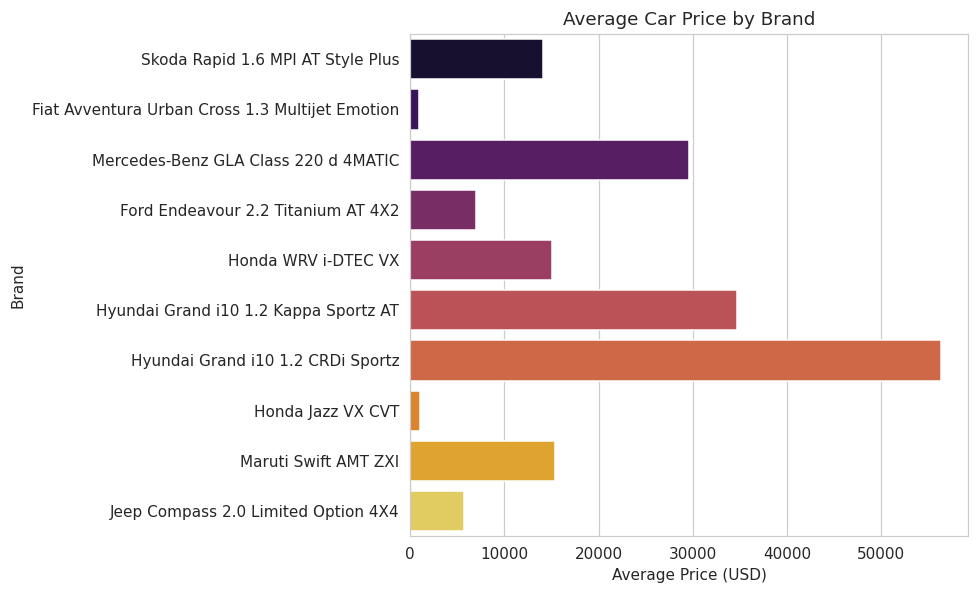

In [ ]:
# Create a horizontal bar chart displaying the average kilometers driven for the top 10 newest models
fig, ax = plt.subplots(figsize=(9, 5.5))
top_10 = brand_summary.head(10)
order = top_10.index
sns.barplot(x=top_10['Avg_KMs'], y=order, ax=ax, hue=order, palette='inferno', legend=False)
# Corrected labels to match the actual data being plotted
ax.set_xlabel('Average Price (USD)')
ax.set_ylabel('Brand')
ax.set_title('Average Car Price by Brand')
plt.tight_layout()
plt.show()

### 5.2 Box Plot — Kilometers Driven Distribution by Fuel Type

We generated a box plot to visualize the spread and median differences of kilometers driven across various fuel types, highlighting distinct vehicle usage patterns for petrol, diesel, and alternative categories.

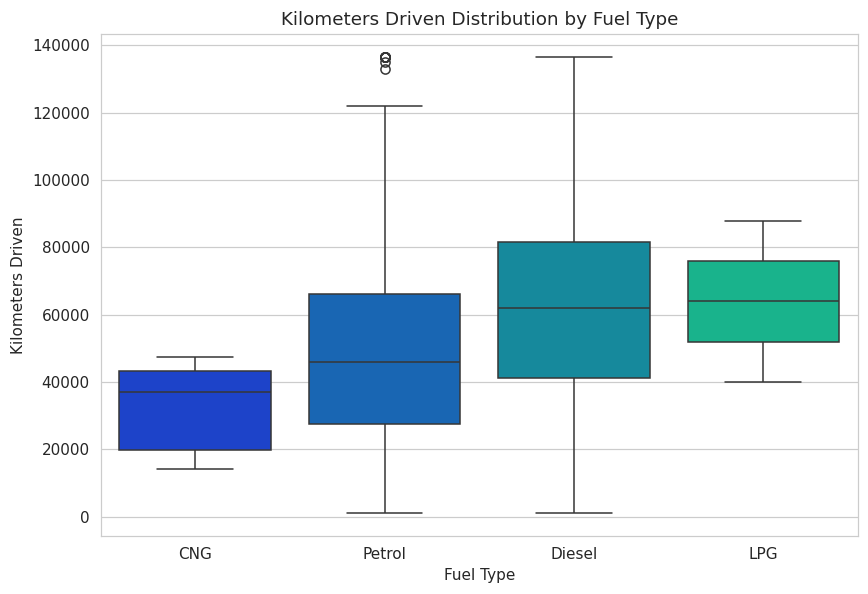

In [ ]:
# Generate a box plot to compare the spread and median of kilometers driven across different fuel types
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(x='Fuel_Type', y='Kilometers_Driven', data=df, ax=ax, hue='Fuel_Type', palette='winter', legend=False)

ax.set_xlabel('Fuel Type')
ax.set_ylabel('Kilometers Driven')
ax.set_title('Kilometers Driven Distribution by Fuel Type')

plt.tight_layout()
plt.show()

### 5.3 Scatter Plot — Year vs Kilometers Driven by Fuel Type
We generated a scatter plot showing the relationship between manufacturing year and kilometers driven, categorized by fuel type to highlight age and usage patterns.

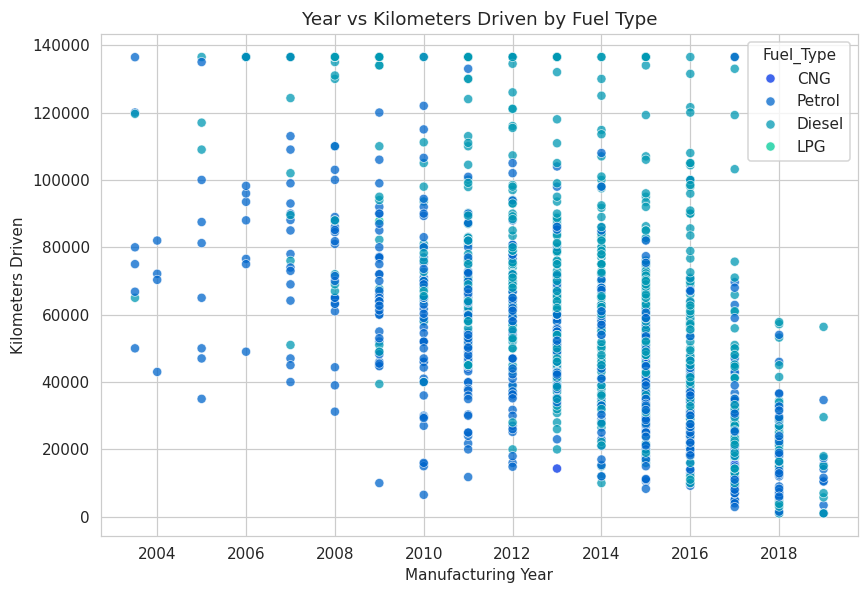

In [ ]:
# Visualize the relationship between manufacturing year and mileage, color-coded by fuel type
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x='Year', y='Kilometers_Driven', hue='Fuel_Type', data=df, ax=ax, alpha=0.75, palette='winter')
ax.set_xlabel('Manufacturing Year')
ax.set_ylabel('Kilometers Driven')
ax.set_title('Year vs Kilometers Driven by Fuel Type')

plt.tight_layout()
plt.show()

### 5.4 Heatmap — Correlation Matrix
We generated a correlation heatmap to visualize linear relationships among numerical features like year, kilometers driven, and seats.

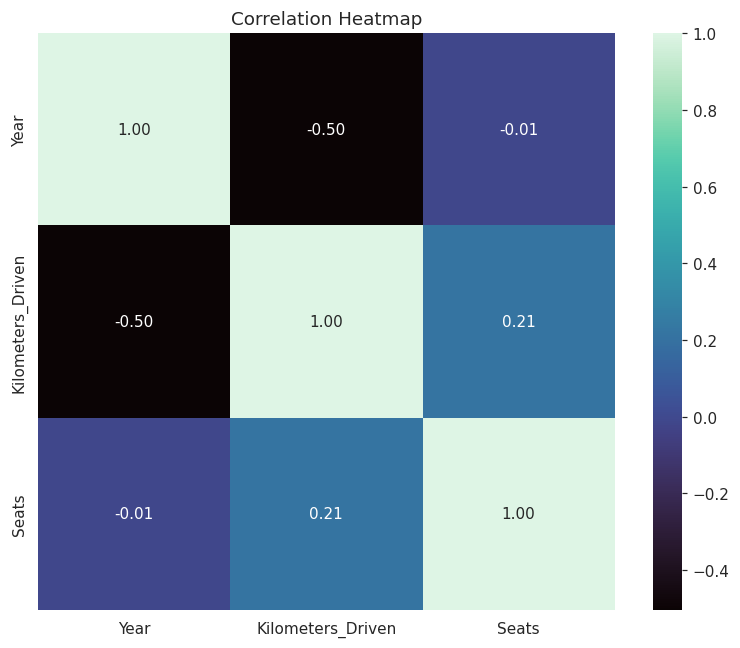

In [ ]:
# Plot an annotated heatmap to easily spot correlations between our numerical variables
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_matrix, annot=True, cmap='mako', fmt='.2f', ax=ax, square=True)
ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## 6. Save Cleaned Dataset
We exported the fully cleaned and processed DataFrame to a new CSV file to preserve all data cleaning, imputation, and formatting steps for future modeling or reporting.

In [ ]:
# Export the final processed dataset to a new CSV, setting index=False to prevent saving a redundant column
df.to_csv('cars_dataset_cleaned.csv', index=False)
print("Cleaned dataset saved as cars_dataset_cleaned.csv")
print("Final shape:", df.shape)

Cleaned dataset saved as cars_dataset_cleaned.csv
Final shape: (1234, 13)


### 7. Key Insight

1. **Vehicle usage varies significantly by model:** Our bar chart analysis of the top vehicle names by average kilometers driven reveals clear differences in how specific car models are utilized, with certain editions accumulating much higher total usage.
2. **Manufacturing Year and Kilometers Driven are heavily linked:** As visualized in the scatter plot, there is a clear relationship between the vehicle's manufacturing year and its accumulated kilometers, demonstrating that older vehicles generally accumulate higher mileage over time.
3. **Fuel type influences vehicle usage patterns:** The box plot analysis of kilometers driven across different fuel types demonstrates distinct distributions and median values, reflecting how vehicles with different propulsion types are driven.
4. **Core features show distinct linear relationships:** The correlation matrix heatmap highlights interactions among numerical variables, notably illustrating how vehicle age relates to accumulated distance and seating capacity.
5. **Data cleaning ensured data integrity:** Properly handling missing entries, removing duplicate rows, and standardizing data formats successfully stabilized the dataset, allowing for clean, distortion-free statistical summaries and visualizations.